# Chain Analysis Tutorial

`sample_joint` writes one history file per sampled parameter and chain. `cmb_lensing/chain_analysis.py` turns a directory of those files into MCMC diagnostics and plots, and can compare the measured posterior with a Fisher forecast. This notebook walks through its Python API on chains that ship with the repository, then shows the equivalent terminal commands.

The data: 10 simulated temperature maps ($128 \times 128$ pixels, $\theta_\mathrm{pix} = 2.5'$, $2.5\,\mu$K-arcmin white noise), 5 chains per map of 6000 sweeps each, sampling $\Omega_c h^2$, $100\,\theta_\mathrm{MC}$ and $\ln(10^{10} A_s)$. The run's settings are in `experimental_results/lcdm_sampling/logA_omch2_theta_MC_100_2dot5uk_white_noise/experimental_details.md`.

In [1]:
import os
import tempfile
import numpy as np
from IPython.display import Image, display

from cmb_lensing import chain_analysis
from cmb_lensing.chain_analysis import (find_history_files, load_chains, gelman_rubin_per_map,
                                        metropolis_acceptance_rate, per_param_analysis,
                                        get_avg_covariance_matrix, get_forecasted_covariance)
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.constants import GROUND_TRUTH

#chain_analysis selects matplotlib's file-only backend on import; switch back for the notebook
%matplotlib inline
import matplotlib.pyplot as plt

#the notebook lives in docs/, so the repository root is one level up
REPO_DIR = ".."
chain_dir = os.path.join(REPO_DIR, "experimental_results", "lcdm_sampling",
                         "logA_omch2_theta_MC_100_2dot5uk_white_noise", "data")
#the box the chains ran on
nside, theta_pix, noise, pol = 128, 2.5, 2.5, "I"
burn_in = 1000

## 1. The input: a directory of history files

Each file is named `<param>_map_<map seed>_chain_<chain index>_history.txt` and holds one value per sweep. `find_history_files` lists what a directory contains. Nothing else has to be specified: the sampled parameters, the maps and the chains per map are all read off the file names.

In [2]:
files = find_history_files(chain_dir)
for name, paths in files.items():
    map_seeds = sorted({map_seed for map_seed, _ in paths})
    print(f"{name}: {len(paths)} files, {len(map_seeds)} maps")
print(os.path.basename(files["omch2"][(234567, 1)]))

logA: 50 files, 10 maps
omch2: 50 files, 10 maps
theta_MC_100: 50 files, 10 maps
omch2_map_234567_chain_1_history.txt


`load_chains` reads them and removes the burn-in. It returns `chains[param][map][sub_chain]`, a 1D array per sub-chain, with maps and sub-chains in the same order for every parameter, so that row $k$ of every parameter is the same sweep. A sub-chain is kept only when every parameter has its file, and one that is no longer than the burn-in is left out.

In [3]:
chains, map_seeds = load_chains(chain_dir, burn_in = burn_in)
print("map seeds:", map_seeds)
print("post-burn-in length of map 0, sub-chain 0:", len(chains["omch2"][0][0]))

Loaded 50 sub-chains of 10 maps for ['theta_MC_100', 'logA', 'omch2']; discarded 0 no longer than the burn-in of 1000
map seeds: [234567, 469134, 703701, 938268, 1172835, 1407402, 1641969, 1876536, 2111103, 2345670]
post-burn-in length of map 0, sub-chain 0: 5000


## 2. Convergence and mixing

These are computed from the unthinned post-burn-in chains.

- `gelman_rubin_per_map`: the Gelman-Rubin $\hat{R}$ across each map's sub-chains. Values near 1 mean the sub-chains agree.
- `metropolis_acceptance_rate`: the fraction of sweeps in which the parameter moved (the sampler is tuned toward about 44%).
- `autocorrelation` and `integrated_autocorrelation_time` (from `cmb_lensing.mcmc_diagnostics`): how many sweeps separate two roughly independent samples.

In [4]:
for name in chains:
    r_hats = gelman_rubin_per_map(chains[name])
    acceptance = metropolis_acceptance_rate(chains[name])
    iats = [integrated_autocorrelation_time(autocorrelation(chain))
            for sub_chains in chains[name] for chain in sub_chains]
    print(f"{name:13s} R-hat mean {np.mean(r_hats):.3f} (max {np.max(r_hats):.3f}), "
          f"acceptance {acceptance:.2f}, mean IAT {np.mean(iats):.0f} sweeps")

theta_MC_100  R-hat mean 1.035 (max 1.061), acceptance 0.40, mean IAT 245 sweeps


logA          R-hat mean 1.011 (max 1.019), acceptance 0.53, mean IAT 85 sweeps


omch2         R-hat mean 1.032 (max 1.071), acceptance 0.57, mean IAT 219 sweeps


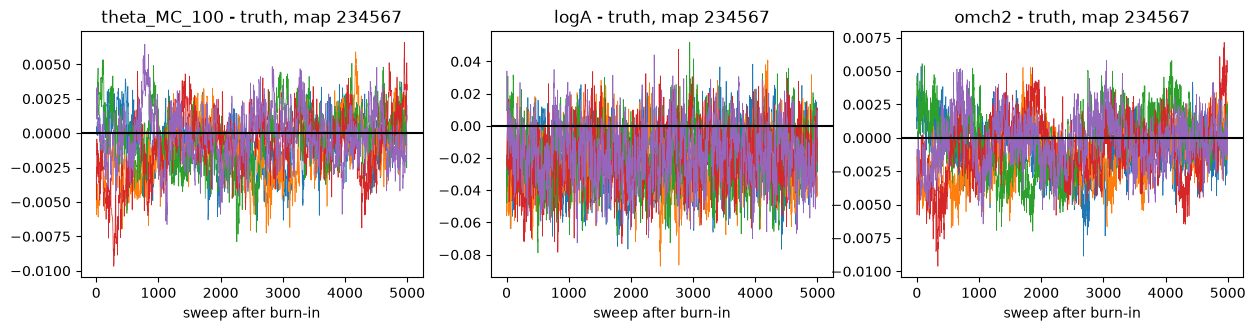

In [5]:
#the five sub-chains of the first map, relative to the value the map was simulated at
figure, axes = plt.subplots(1, 3, figsize = (15, 3.2))
for axis, name in zip(axes, chains):
    for chain in chains[name][0]:
        axis.plot(chain - GROUND_TRUTH[name], lw = 0.5)
    axis.axhline(0, color = "black")
    axis.set_title(f"{name} - truth, map {map_seeds[0]}")
    axis.set_xlabel("sweep after burn-in")
plt.show()

## 3. One parameter at a time

`per_param_analysis` writes every single-parameter plot into a folder and returns the summary numbers. Before plotting it thins each sub-chain by its own integrated autocorrelation time (`should_thin = False` turns that off), so the kernel density estimates are built from nearly independent points.

The **product distribution** is the renormalized product of the per-map posteriors: the posterior one would get from all 10 maps together. Its mean should sit within about one product standard deviation of the truth; the z-score is (truth − product mean) / product std. The errors in brackets are Monte Carlo errors from a bootstrap over each map's thinned chain, in units of the last digit: `0.1098(1)` means $0.1098 \pm 0.0001$.

In [6]:
out_dir = tempfile.mkdtemp(prefix = "chain_analysis_tutorial_")
omch2_dir = os.path.join(out_dir, "omch2")
summary = per_param_analysis(chains["omch2"], GROUND_TRUTH["omch2"], "omch2", omch2_dir)
for key in ("product_mean", "product_std", "product_z_score", "avg_sigma_single"):
    print(f"{key:18s} {summary[key]:.6g}")
print(sorted(os.listdir(omch2_dir)))


Beginning omch2 analysis
omch2 Gelman-Rubin R-hat per map = [1.02421836 1.01574752 1.02635395 1.01324034 1.07142078 1.04218345
 1.01451204 1.03888194 1.01515923 1.06119046]
omch2 Gelman-Rubin R-hat mean = 1.0322908080645767, std = 0.019632214896999126
omch2 Metropolis-Hastings acceptance rate = 0.5686


product_mean       0.109225
product_std        0.000673064
product_z_score    0.231762
avg_sigma_single   0.00200539
['omch2_all_chain_marginals.png', 'omch2_all_chain_trace.png', 'omch2_auto_correlation.png', 'omch2_integrated_autocorrelation_times.png', 'omch2_mean_distributions.png', 'omch2_mean_histogram.png']


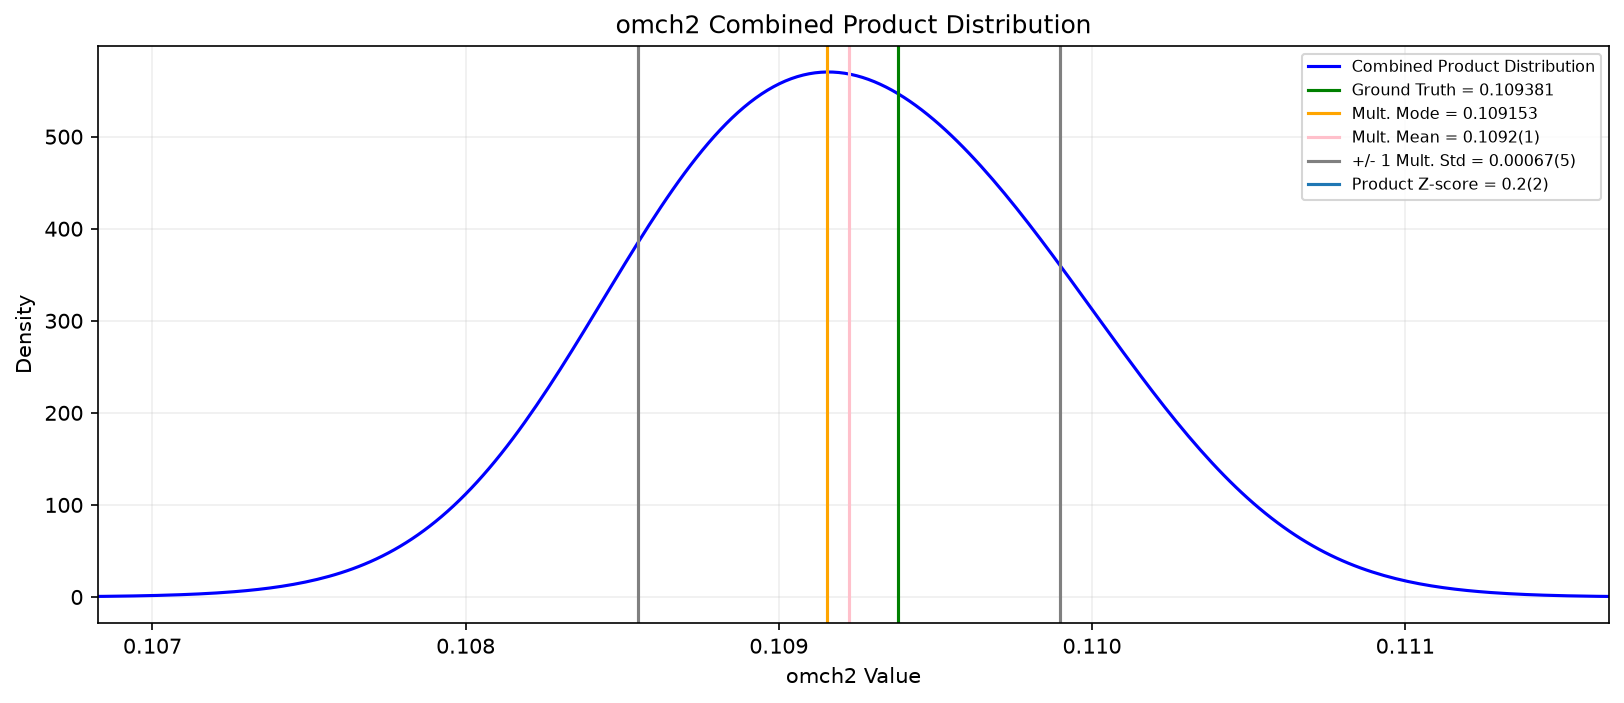

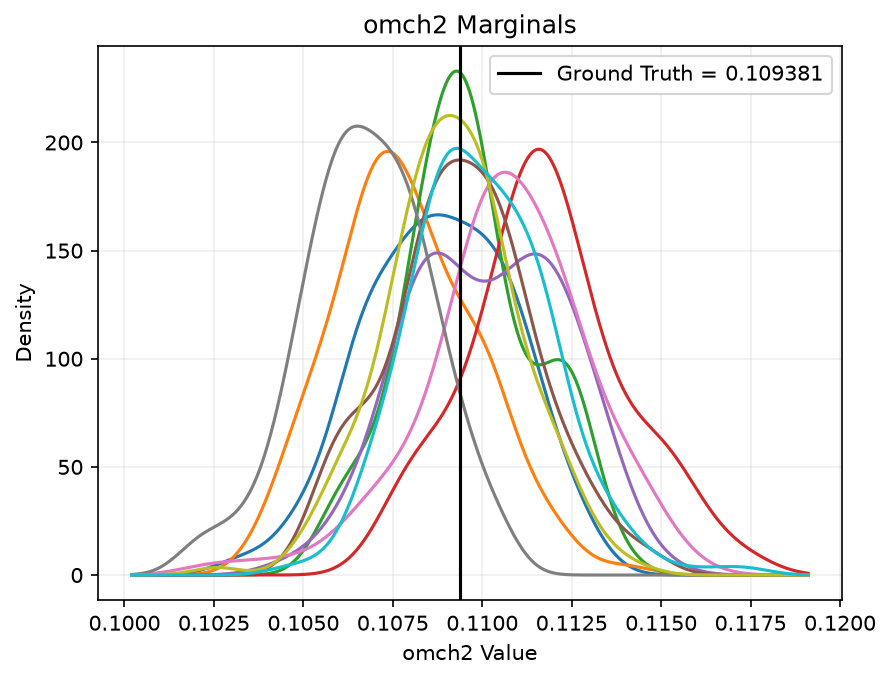

In [7]:
display(Image(os.path.join(omch2_dir, "omch2_mean_distributions.png")))
display(Image(os.path.join(omch2_dir, "omch2_all_chain_marginals.png")))

## 4. The joint posterior

`get_avg_covariance_matrix` computes one covariance matrix per map (its unthinned sub-chains concatenated) and averages them over maps. Samples from different maps are never pooled: each map has its own posterior mean, and pooling would add the scatter of those means to the widths. The errors are a delete-one-map jackknife.

In [8]:
covariance, param_names, covariance_error, sigma_error = get_avg_covariance_matrix(chains)
for name, variance, error in zip(param_names, np.diag(covariance), sigma_error):
    print(f"sigma({name}) = {np.sqrt(variance):.5f} +/- {error:.5f}")

sigma(theta_MC_100) = 0.00218 +/- 0.00005
sigma(logA) = 0.01920 +/- 0.00016
sigma(omch2) = 0.00203 +/- 0.00003


## 5. Everything at once: `main`

`chain_analysis.main` runs all of the above for every sampled parameter and writes the joint plots. By default the output goes to `<chain_dir>/chain_analysis_output/`; here it goes to a temporary folder. `pol` (`"I"`, `"P"` or `"IP"`) records which data the chains saw and only labels the plots: the chain analysis itself is the same for temperature, polarization and joint runs.

In [9]:
results = chain_analysis.main(chain_dir, nside = nside, theta_pix = theta_pix, noise = noise,
                              pol = pol, burn_in = burn_in, out_dir = out_dir)
print(sorted(results))
print(sorted(os.listdir(os.path.join(out_dir, "joint_information"))))

Loaded 50 sub-chains of 10 maps for ['theta_MC_100', 'logA', 'omch2']; discarded 0 no longer than the burn-in of 1000

Beginning theta_MC_100 analysis
theta_MC_100 Gelman-Rubin R-hat per map = [1.021775   1.0220287  1.04157562 1.0272714  1.05366426 1.04632258
 1.01593748 1.03472499 1.02654067 1.0612903 ]
theta_MC_100 Gelman-Rubin R-hat mean = 1.035113099417908, std = 0.014313449199273708
theta_MC_100 Metropolis-Hastings acceptance rate = 0.3989



Beginning logA analysis
logA Gelman-Rubin R-hat per map = [1.00265065 1.01055905 1.01360383 1.01458794 1.01271052 1.01205835
 1.00696552 1.00733522 1.00639833 1.01914651]
logA Gelman-Rubin R-hat mean = 1.0106015921061031, std = 0.004574567238913705
logA Metropolis-Hastings acceptance rate = 0.5309



Beginning omch2 analysis
omch2 Gelman-Rubin R-hat per map = [1.02421836 1.01574752 1.02635395 1.01324034 1.07142078 1.04218345
 1.01451204 1.03888194 1.01515923 1.06119046]
omch2 Gelman-Rubin R-hat mean = 1.0322908080645767, std = 0.019632214896999126
omch2 Metropolis-Hastings acceptance rate = 0.5686



Beginning joint parameter analysis



Plots written to /tmp/chain_analysis_tutorial__cz45mwz
['chains', 'forecast_covariance', 'map_seeds', 'measured_covariance', 'measured_covariance_error', 'measured_sigma_error', 'out_dir', 'param_names', 'summaries']
['correlation_matrix_empirical.png', 'covariance_matrix_empirical.png', 'triangle_plot.png', 'z_scores.png']


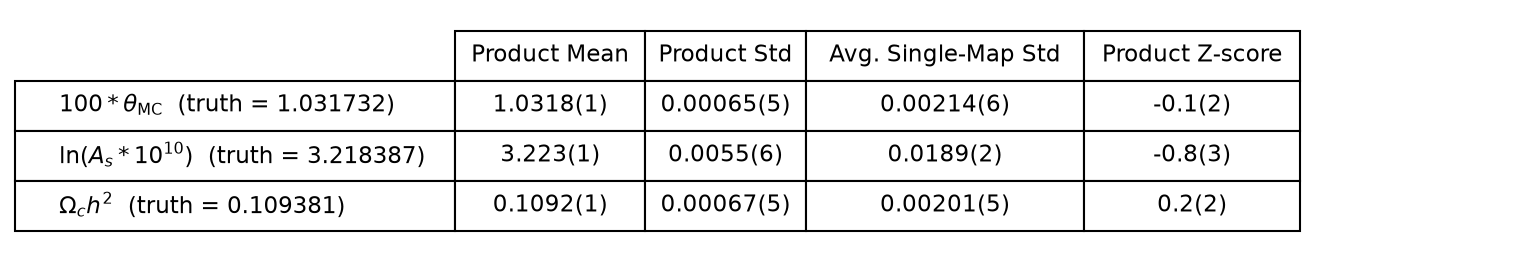

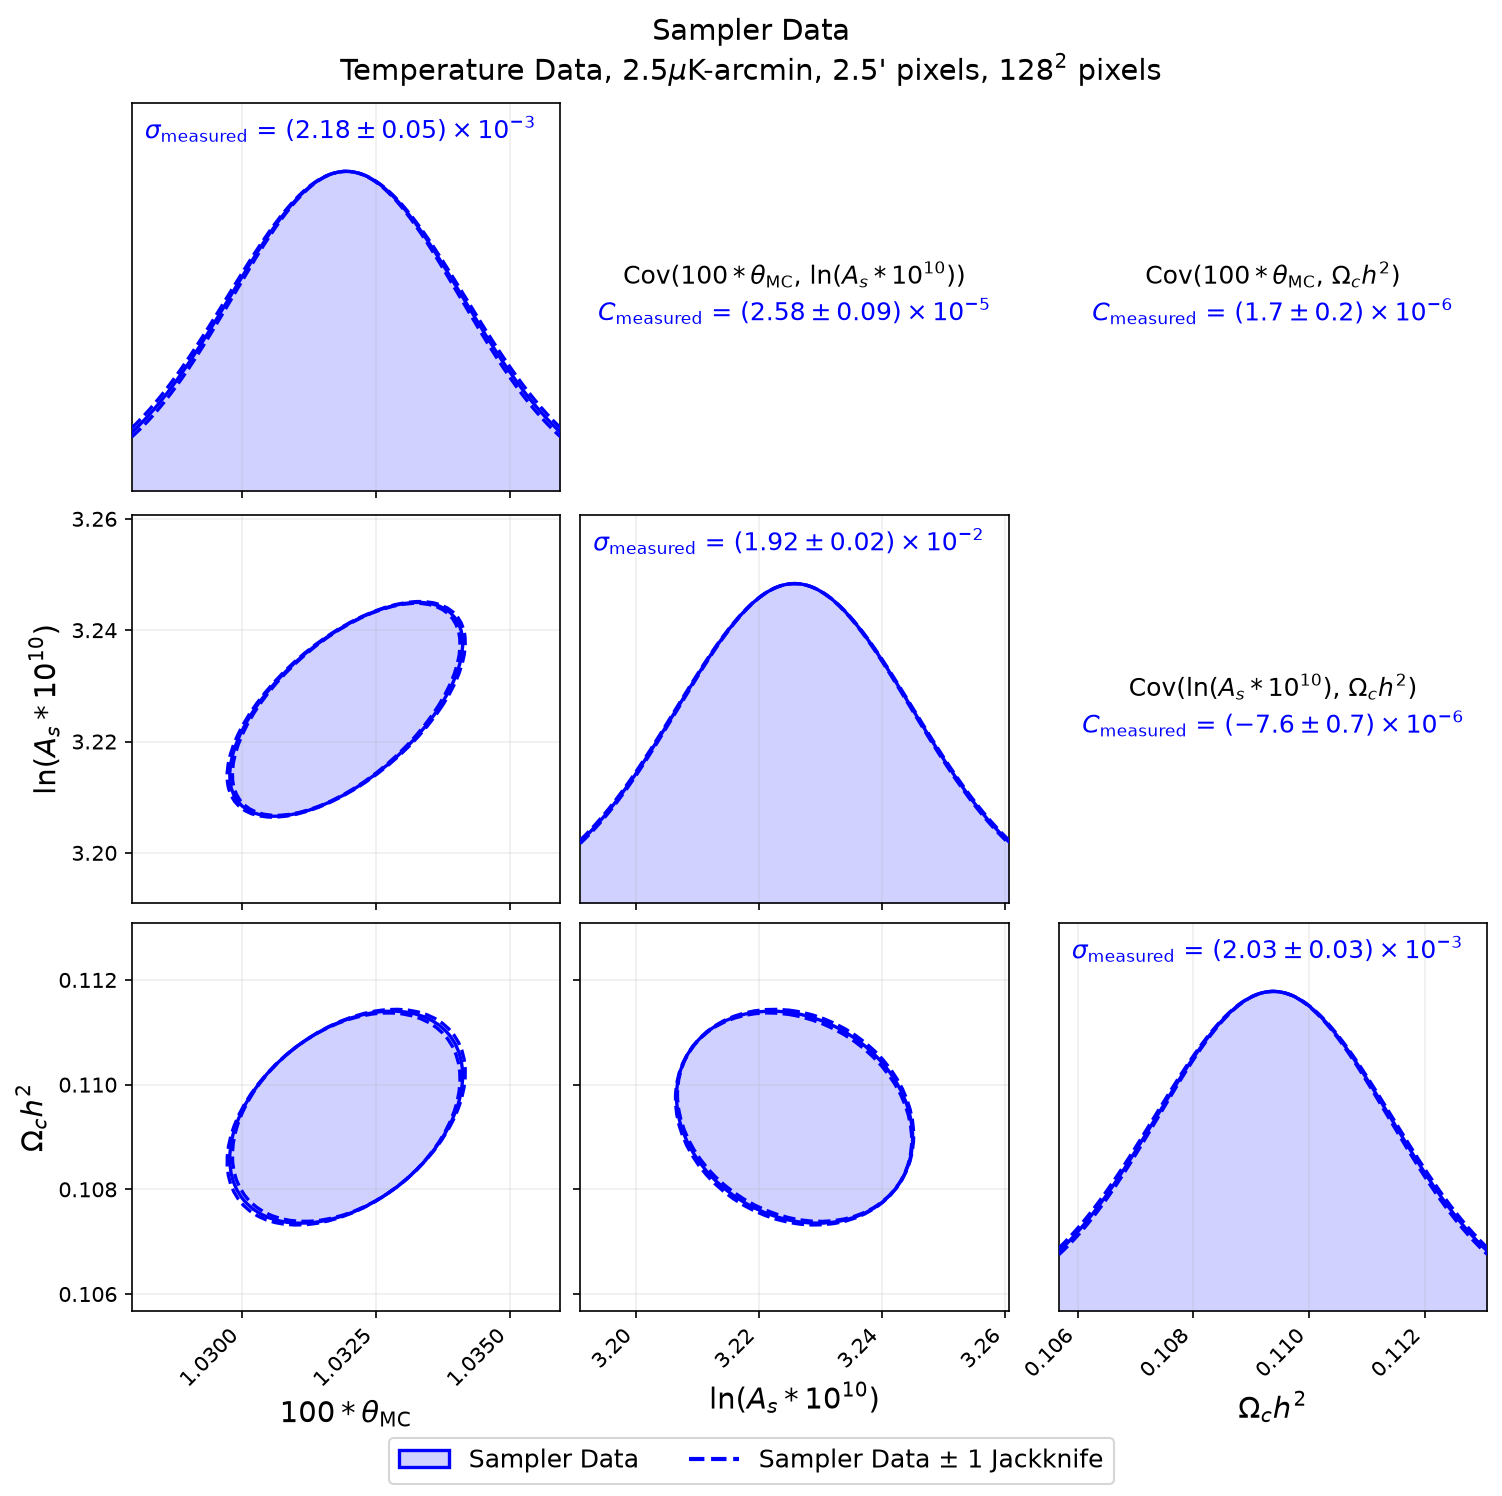

In [10]:
joint_dir = os.path.join(out_dir, "joint_information")
display(Image(os.path.join(joint_dir, "z_scores.png")))
display(Image(os.path.join(joint_dir, "triangle_plot.png")))

## 6. Comparing with the Fisher forecast

The forecast is off unless `run_fisher = True`. It needs a merged `delensed_covariance.npz` (see the Delensed Covariances pipeline page), measured at the chains' box, noise level and `pol`, which supplies its field blocks. There is no fallback: asking for the forecast without the file is an error. The chains here saw temperature data, so `pol = "I"`; for `"P"` or `"IP"` chains pass that `pol` and a delensed covariance measured at it (`include_bb = False` then leaves the delensed B modes out of the forecast).

In [11]:
try:
    chain_analysis.main(chain_dir, noise = noise, out_dir = out_dir, run_fisher = True)
except ValueError as error:
    print("ValueError:", error)

ValueError: run_fisher needs delensed_covariance, a merged delensed_covariance.npz: there is no analytic delensing fallback


The merged covariance files are too large for git, so the cells below use local copies under `get_delensed_field_covariance/delensed_field_covariance_data/` and `measure_phi_noise/`; point the paths at your own files.

The forecast's lensing reconstruction noise $N_\phi$ has three options:

| Option | $N_\phi$ |
|---|---|
| default | the quadratic-estimate $N^{(0)}$ of this box, built like `load_sim`'s, with the unlensed $C_\ell^{TT}$ in the response and the filter |
| `qe_filter = "lensed"` | the same, with the lensed $C_\ell^{TT}$ in the filter (the response stays unlensed) |
| `phi_noise = <npz>` | a measured per-mode matrix: the `nphi` of a merged `map_joint_phi_noise.npz` or `sampler_phi_noise.npz` |

In [12]:
delensed_covariance = os.path.join(REPO_DIR, "get_delensed_field_covariance",
                                   "delensed_field_covariance_data",
                                   "delensed_covariance_output_qe_filter_unlensed_response_unlensed_2.5uk",
                                   "delensed_covariance.npz")
results = chain_analysis.main(chain_dir, nside = nside, theta_pix = theta_pix, noise = noise,
                              pol = pol, burn_in = burn_in, out_dir = out_dir,
                              run_fisher = True, delensed_covariance = delensed_covariance)

Loaded 50 sub-chains of 10 maps for ['theta_MC_100', 'logA', 'omch2']; discarded 0 no longer than the burn-in of 1000

Beginning theta_MC_100 analysis
theta_MC_100 Gelman-Rubin R-hat per map = [1.021775   1.0220287  1.04157562 1.0272714  1.05366426 1.04632258
 1.01593748 1.03472499 1.02654067 1.0612903 ]
theta_MC_100 Gelman-Rubin R-hat mean = 1.035113099417908, std = 0.014313449199273708
theta_MC_100 Metropolis-Hastings acceptance rate = 0.3989



Beginning logA analysis
logA Gelman-Rubin R-hat per map = [1.00265065 1.01055905 1.01360383 1.01458794 1.01271052 1.01205835
 1.00696552 1.00733522 1.00639833 1.01914651]
logA Gelman-Rubin R-hat mean = 1.0106015921061031, std = 0.004574567238913705
logA Metropolis-Hastings acceptance rate = 0.5309



Beginning omch2 analysis
omch2 Gelman-Rubin R-hat per map = [1.02421836 1.01574752 1.02635395 1.01324034 1.07142078 1.04218345
 1.01451204 1.03888194 1.01515923 1.06119046]
omch2 Gelman-Rubin R-hat mean = 1.0322908080645767, std = 0.019632214896999126
omch2 Metropolis-Hastings acceptance rate = 0.5686



Beginning joint parameter analysis



Plots written to /tmp/chain_analysis_tutorial__cz45mwz


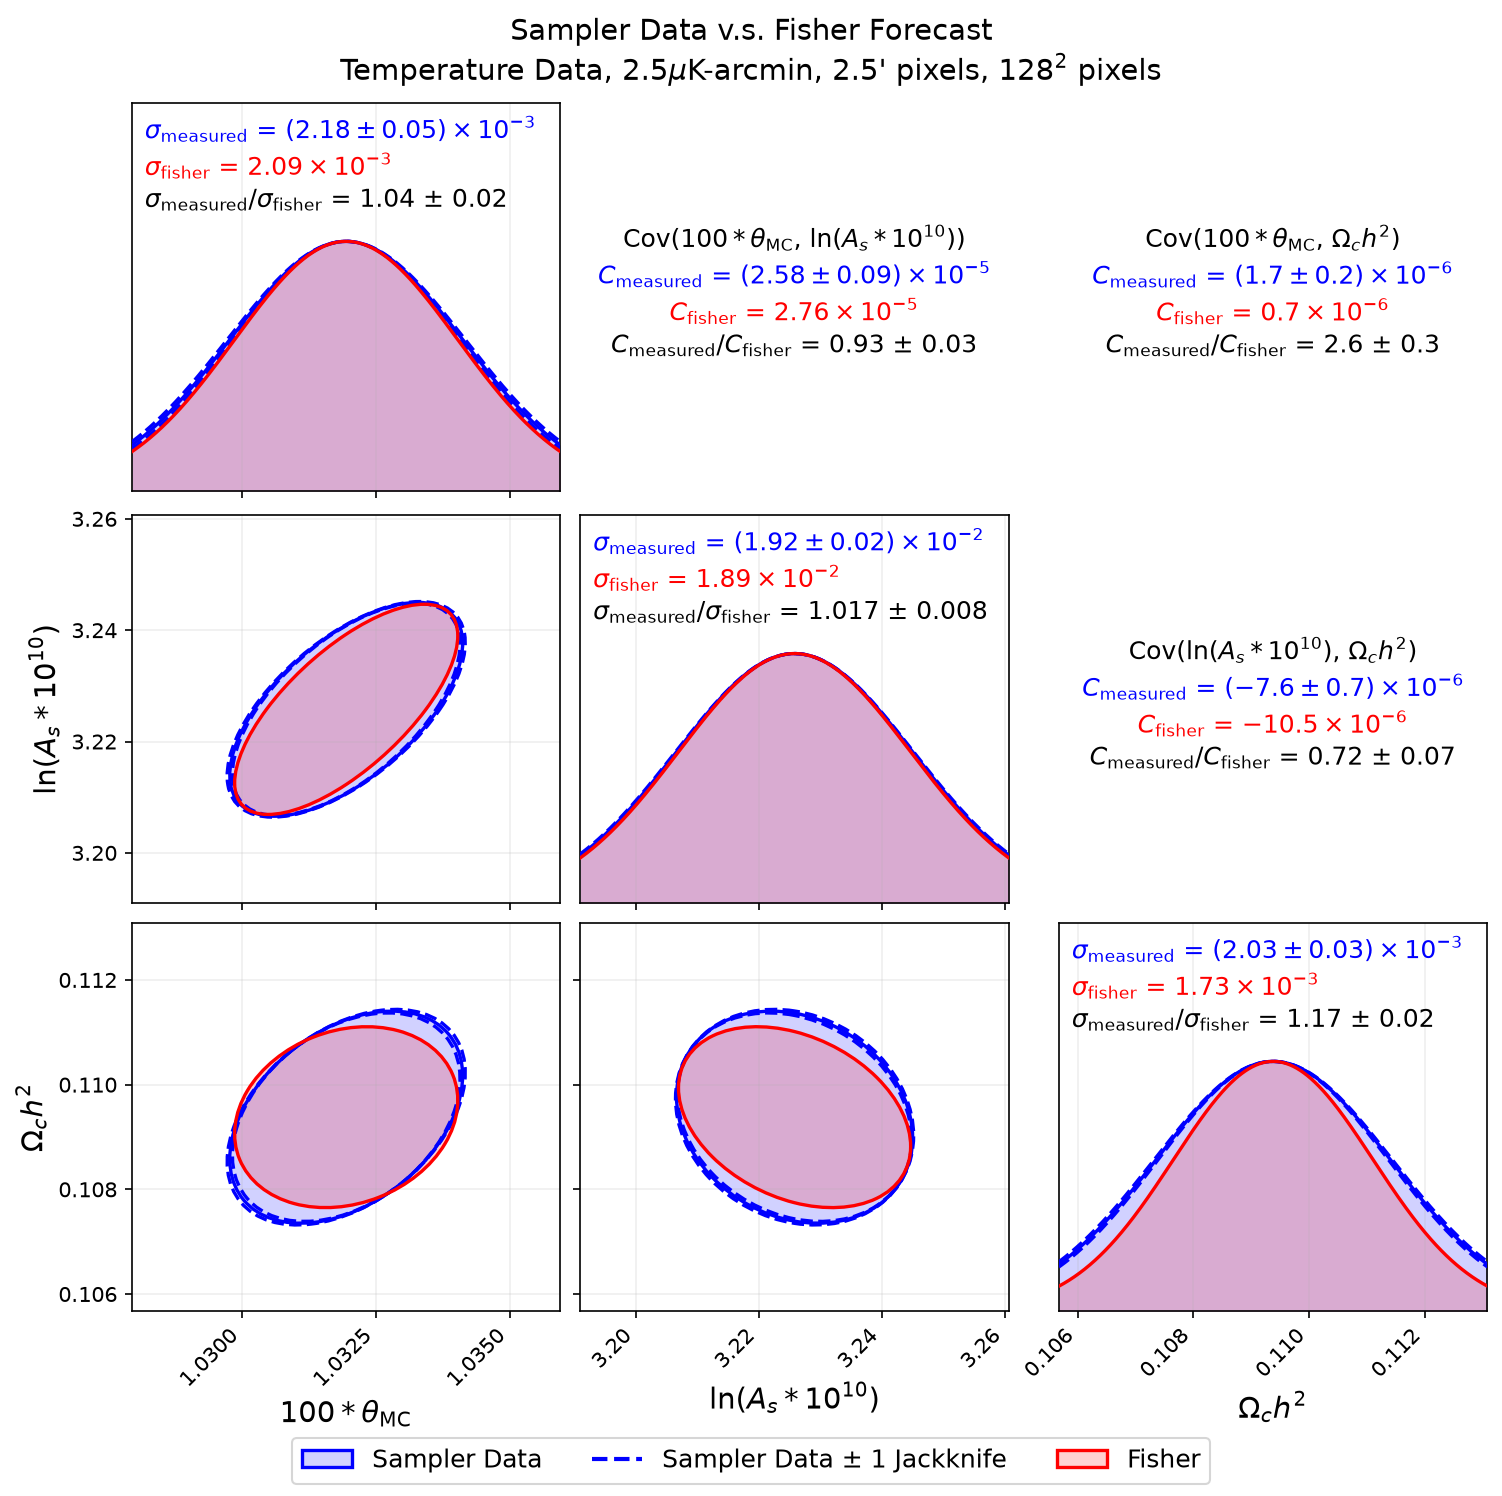

In [13]:
display(Image(os.path.join(joint_dir, "triangle_plot.png")))

Blue is the chains' posterior (dashed: plus and minus one jackknife error), red the forecast, both centred on the chains' means. Each diagonal panel gives the measured and forecast widths and their ratio; each upper-right cell gives the covariance of the mirrored pair. With the forecast, `joint_information/` also holds the forecast's covariance and correlation matrices and the forecast-over-chains ratios.

`get_forecasted_covariance` returns the forecast covariance alone, in the package's standard parameter order (the order `load_chains` uses). Below, the measured widths are compared with the forecast under each $N_\phi$ option. The delensed covariance used here was built with the unlensed-filter $N^{(0)}$, so the other two rows mix reconstruction noises and are only illustrations of the interface.

In [14]:
map_joint_phi_noise = os.path.join(REPO_DIR, "measure_phi_noise", "get_map_joint_phi_noise",
                                   "map_joint_phi_noise_new", "map_joint_phi_noise_output_2.5uk",
                                   "map_joint_phi_noise.npz")
param_names = results["param_names"]
forecasts = {"QE N0, unlensed filter": results["forecast_covariance"],
             "QE N0, lensed filter": get_forecasted_covariance(
                 nside, theta_pix, noise, param_names, delensed_covariance, qe_filter = "lensed"),
             "measured (map_joint)": get_forecasted_covariance(
                 nside, theta_pix, noise, param_names, delensed_covariance,
                 phi_noise = map_joint_phi_noise)}

In [15]:
measured_sigmas = np.sqrt(np.diag(results["measured_covariance"]))
print(f"{'sigma_measured / sigma_fisher':30s}" + "".join(f"{name:>14s}" for name in param_names))
for label, forecast_covariance in forecasts.items():
    ratios = measured_sigmas / np.sqrt(np.diag(forecast_covariance))
    print(f"{label:30s}" + "".join(f"{ratio:14.3f}" for ratio in ratios))
print(f"{'jackknife error on the ratio':30s}"
      + "".join(f"{error:14.3f}" for error in results["measured_sigma_error"]
                / np.sqrt(np.diag(forecasts["QE N0, unlensed filter"]))))

sigma_measured / sigma_fisher   theta_MC_100          logA         omch2
QE N0, unlensed filter                 1.044         1.017         1.172
QE N0, lensed filter                   1.007         1.016         1.002
measured (map_joint)                   1.001         1.016         0.979
jackknife error on the ratio           0.023         0.008         0.020


## 7. From the terminal

The same analysis, run from the repository root:

```bash
#MCMC plots only
python -m cmb_lensing.chain_analysis <chain_dir> --nside 128 --theta_pix 2.5 --noise 2.5 --burn_in 1000

#with the forecast (unlensed-filter QE N0)
python -m cmb_lensing.chain_analysis <chain_dir> --noise 2.5 --run_fisher \
    --delensed_covariance <delensed_covariance.npz>

#lensed C_TT in the QE filter, or a measured phi noise
python -m cmb_lensing.chain_analysis <chain_dir> --noise 2.5 --run_fisher \
    --delensed_covariance <delensed_covariance.npz> --qe_filter lensed
python -m cmb_lensing.chain_analysis <chain_dir> --noise 2.5 --run_fisher \
    --delensed_covariance <delensed_covariance.npz> --phi_noise <map_joint_phi_noise.npz>
```

Other flags: `--pol I|P|IP`, `--no_bb`, `--no_thin`, `--out_dir <folder>` and `--camb_lmax`. `python -m cmb_lensing.chain_analysis --help` lists them all.